# 02 · Evaluación final y análisis de errores

Modelo elegido en validación: **item_knn** (ver `reports/results/model_selection.md`).
Esta libreta lee únicamente los CSV y figuras generados por `src/final_eval.py` y `src/error_analysis.py`.
No se reajusta nada ni se vuelve a tocar test.

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent
R = ROOT / "reports/results"
FIG = ROOT / "reports/figures"

def load(name):
    return pd.read_csv(R / name)

rating = load("errors_by_rating.csv")
activity = load("errors_by_user_activity.csv")
pop = load("errors_by_movie_popularity.csv")
genre = load("errors_by_genre.csv")
decade = load("errors_by_decade.csv")
cold = load("errors_cold_movie.csv")
test = load("test_results.csv")
print("archivos cargados:", [p.name for p in sorted(R.glob("errors_*.csv"))])

archivos cargados: ['errors_by_cluster.csv', 'errors_by_decade.csv', 'errors_by_genre.csv', 'errors_by_movie_popularity.csv', 'errors_by_rating.csv', 'errors_by_user_activity.csv', 'errors_cold_movie.csv']


## Resultado global en test

La tabla siguiente es la salida de `final_eval.py` (test leído una sola vez, modelos congelados en validación).

In [2]:
cols = [c for c in ["modelo","test_rmse","test_mae","ndcg@10","recall@10","val_rmse"] if c in test.columns]
display(test[cols].round(4))
best_row = test[test.modelo.str.contains("Item-KNN", case=False, na=False)].iloc[0]
print("Modelo elegido:", best_row["modelo"])
print("test RMSE:", round(best_row.test_rmse, 4), "| test MAE:", round(best_row.test_mae, 4))
print("NDCG@10:", round(best_row["ndcg@10"], 4), "| Recall@10:", round(best_row["recall@10"], 4))

,modelo,test_rmse,test_mae,ndcg@10,recall@10,val_rmse
0,Baseline (sesgo usuario+película),0.8810,0.6697,0.2447,0.2944,0.8668
1,Baseline ranking (popularidad),NaN,NaN,0.5674,0.6390,NaN
2,Item-KNN,0.8450,0.6349,0.4029,0.4330,0.8198
3,Funk SVD,0.8453,0.6400,0.2951,0.3320,0.8261
4,Ridge + features,0.8742,0.6650,0.3328,0.3789,0.8578
5,HistGB + features,0.8635,0.6551,0.2857,0.3229,0.8472
6,Mejor de AutoML (FLAML),0.8642,0.6557,0.2834,0.3163,NaN


Modelo elegido: Item-KNN
test RMSE: 0.845 | test MAE: 0.6349
NDCG@10: 0.4029 | Recall@10: 0.433


El mejor modelo manual obtiene **RMSE 0.8450** y **MAE 0.6349** en test.
El baseline de sesgos obtiene **RMSE 0.8810**: la mejora es de **4.1%**.

## Regresión hacia la media por rating real

El sesgo (`pred - real`) es positivo en ratings bajos y negativo en ratings altos: el modelo “tira” hacia el centro de la escala.
Esto es esperable con RMSE y features de sesgo, pero es la limitación más visible para el usuario.

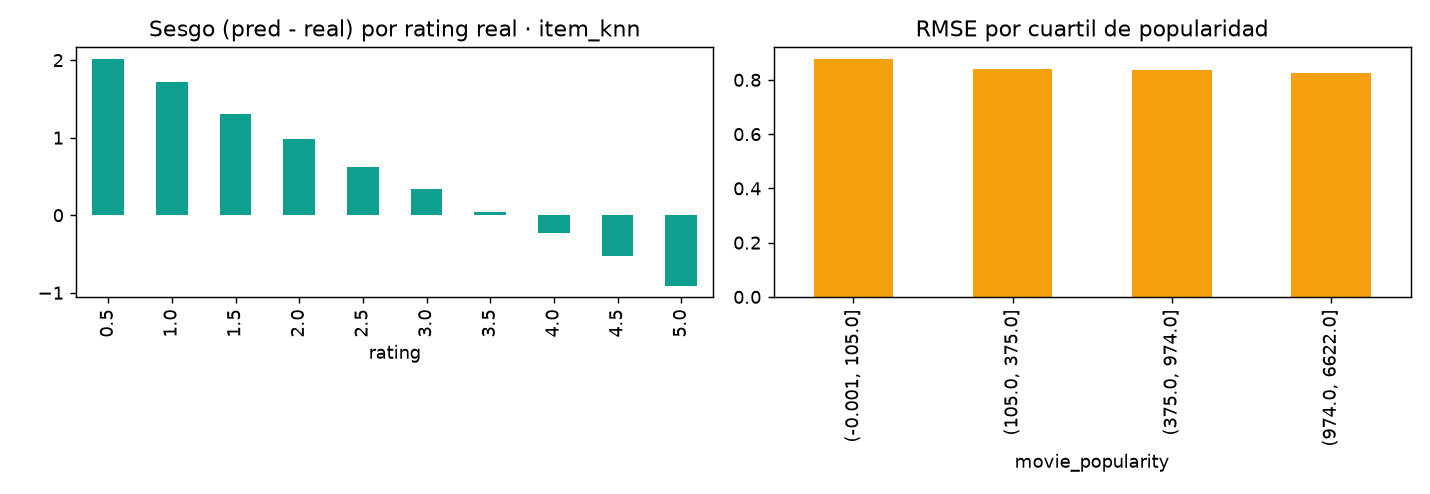

,rating,n,bias,mae,rmse
0,0.5,5373,2.020,2.020,2.212
1,1.0,11214,1.722,1.724,1.875
2,1.5,5745,1.301,1.312,1.460
3,2.0,22905,0.978,1.006,1.153
4,2.5,18927,0.625,0.693,0.829
5,3.0,66027,0.341,0.502,0.621
6,3.5,47811,0.046,0.365,0.465
7,4.0,87417,-0.234,0.405,0.528
8,4.5,31168,-0.531,0.562,0.698
9,5.0,40301,-0.907,0.907,1.043


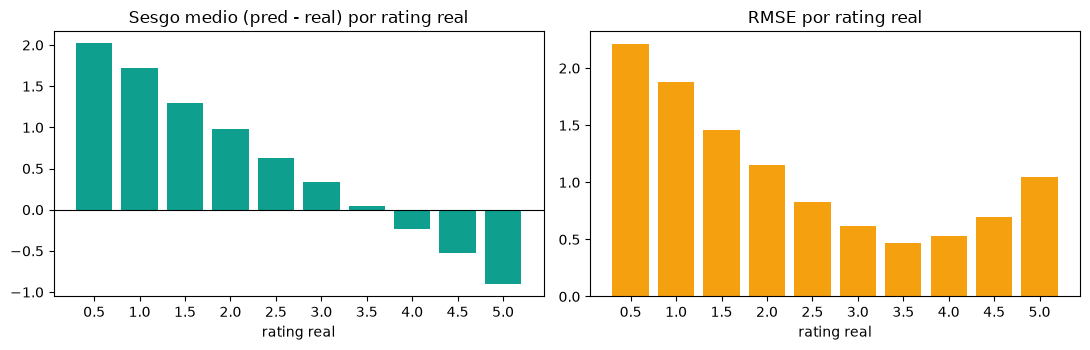

In [3]:
display(Image(filename=FIG / "error_segments.png"))
display(rating.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(rating.rating.astype(str), rating.bias, color="#0f9f8f"); ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_title("Sesgo medio (pred - real) por rating real"); ax[0].set_xlabel("rating real")
ax[1].bar(rating.rating.astype(str), rating.rmse, color="#f5a00f"); ax[1].set_title("RMSE por rating real"); ax[1].set_xlabel("rating real")
plt.tight_layout(); plt.show()

Los extremos son los más difíciles: rating **0.5** tiene sesgo **+2.020** y RMSE **2.212**; rating **5.0** tiene sesgo **-0.907** y RMSE **1.043**.
El mejor comportamiento está en **3.5** (RMSE **0.465**), donde se concentra buena parte del histórico.

## Error según actividad del usuario

Se usan cuartiles de actividad calculados con train. Los usuarios con menos historial tienen más error, coherente con la dificultad de estimar sesgos/factores con pocas observaciones.

,user_activity,n,bias,mae,rmse
0,"(227.0, 499.0]",84296,0.092,0.613,0.815
1,"(499.0, 3702.0]",83937,0.117,0.599,0.796
2,"(7.999, 96.0]",85440,-0.009,0.680,0.901
3,"(96.0, 227.0]",83215,0.075,0.647,0.864


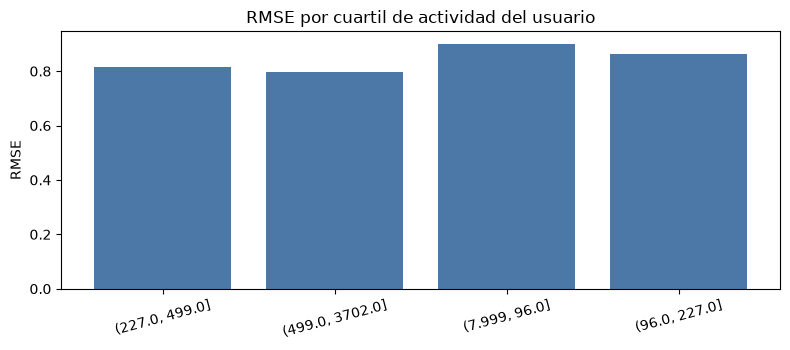

In [4]:
display(activity.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(activity.user_activity, activity.rmse, color="#4c78a8"); ax.set_ylabel("RMSE"); ax.set_title("RMSE por cuartil de actividad del usuario")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

El cuartil de menor actividad (`(7.999, 96.0]`) tiene RMSE **0.9014**; el de mayor actividad (`(499.0, 3702.0]`) baja a **0.7957**.
La diferencia es de **0.1057** puntos de RMSE. No se eliminan usuarios de baja actividad: se reporta el segmento.

## Error según popularidad de la película

Las películas del cuartil menos popular (`{pop_lo.movie_popularity}`) tienen peor RMSE que las del más popular (`{pop_hi.movie_popularity}`). La cola larga sigue siendo el segmento más costoso.

,movie_popularity,n,bias,mae,rmse
0,"(-0.001, 105.0]",84509,0.093,0.664,0.876
1,"(105.0, 375.0]",84015,0.064,0.633,0.841
2,"(375.0, 974.0]",84301,0.060,0.628,0.835
3,"(974.0, 6622.0]",84063,0.057,0.615,0.827


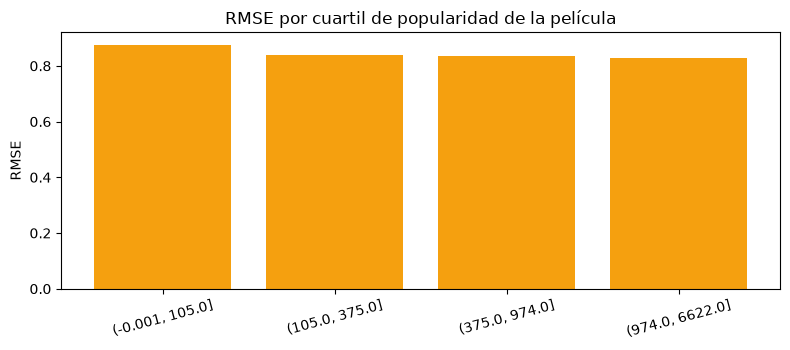

In [5]:
display(pop.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(pop.movie_popularity, pop.rmse, color="#f5a00f"); ax.set_ylabel("RMSE"); ax.set_title("RMSE por cuartil de popularidad de la película")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

El cuartil menos popular (`(-0.001, 105.0]`) tiene RMSE **0.8765**; el más popular (`(974.0, 6622.0]`), **0.8268**.
La brecha es de **0.0497** puntos: la contracción ayuda, pero no elimina la desventaja de la cola larga.

## Géneros difíciles

Un rating puede pertenecer a varios géneros; por eso los conteos suman más que el total de test.

,genre,n,bias,mae,rmse
0,(no genres listed),549,-0.006,0.625,0.828
1,Action,94920,0.073,0.624,0.830
2,Adventure,72957,0.063,0.624,0.833
3,Animation,22322,0.074,0.621,0.836
4,Children,29048,0.068,0.646,0.854
5,Comedy,120510,0.074,0.655,0.867
6,Crime,53033,0.083,0.604,0.814
7,Documentary,5663,-0.051,0.631,0.852
8,Drama,149188,0.054,0.620,0.828
9,Fantasy,37059,0.073,0.642,0.856


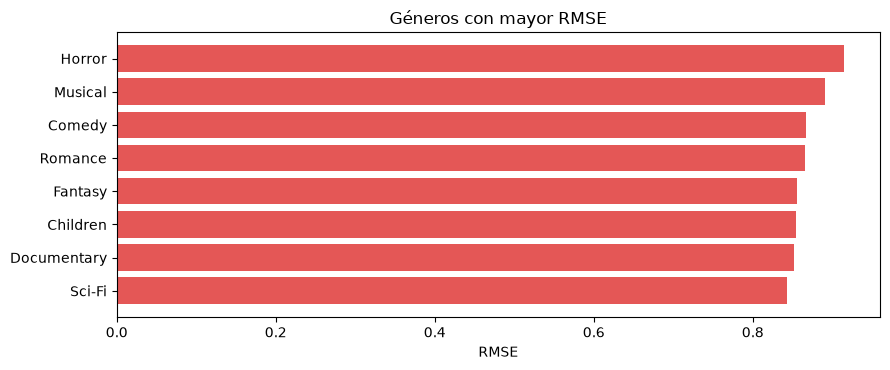

Mejores géneros por RMSE:
   genre     n   rmse
 Western  6163 0.8039
   Crime 53033 0.8143
     War 15316 0.8144
 Mystery 27169 0.8208
Thriller 89001 0.8253


In [6]:
display(genre.round(3))
worst = genre.sort_values("rmse", ascending=False).head(8)
best = genre.sort_values("rmse").head(5)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(worst.genre[::-1], worst.rmse[::-1], color="#e45756"); ax.set_xlabel("RMSE"); ax.set_title("Géneros con mayor RMSE")
plt.tight_layout(); plt.show()
print("Mejores géneros por RMSE:")
print(best[["genre","n","rmse"]].to_string(index=False))

Los peores son **Horror** (RMSE **0.9143**, n=27310), **Musical** (**0.8910**) y **Comedy** (**0.8672**).
Los mejores son **Western** (**0.8039**) y **Crime** (**0.8143**). La diferencia entre el peor y el mejor género es de **0.1104**.

## Décadas difíciles

La década se calcula a partir del año del título. Las décadas con pocos ratings tienen estimaciones inestables; se muestran los conteos para no sobreinterpretar.

,decade,n,bias,mae,rmse
0,1900,19,0.169,0.616,0.906
1,1910,25,0.082,0.849,1.102
2,1920,492,0.126,0.652,0.896
3,1930,2361,0.091,0.617,0.818
4,1940,3688,0.078,0.605,0.822
5,1950,6207,0.050,0.609,0.819
6,1960,9270,0.064,0.618,0.827
7,1970,14947,0.084,0.635,0.848
8,1980,38032,0.085,0.637,0.840
9,1990,104209,0.060,0.663,0.871


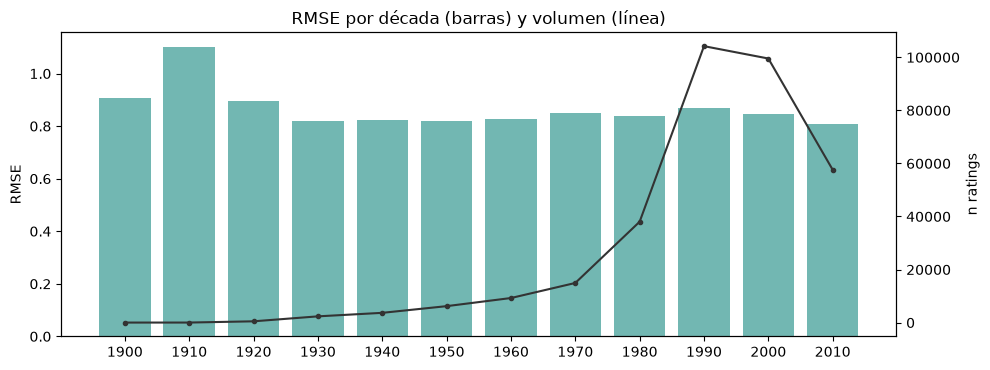

In [7]:
display(decade.round(3))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(decade.decade.astype(str), decade.rmse, color="#72b7b2")
ax2 = ax.twinx(); ax2.plot(decade.decade.astype(str), decade.n, color="#333", marker="o", ms=3)
ax.set_ylabel("RMSE"); ax2.set_ylabel("n ratings"); ax.set_title("RMSE por década (barras) y volumen (línea)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

El peor RMSE está en **1910** (**1.1018**) pero solo tiene **25** ratings: no es concluyente.
Entre las décadas con volumen relevante, **1990** tiene RMSE **0.8708** con n=104209; **2010** tiene **0.8077** con n=57619.
La tendencia no es monotónica; el año por sí solo no explica el error.

## Cold start de películas

No hay usuarios fríos en test (`pct_ratings_cold_user = 0.0`). Solo un 0.0368% de los ratings de test corresponde a películas no vistas en train.

In [8]:
display(cold.round(3))
print("ratings cold movie:", int(cold.loc[cold.cold_movie.astype(str)=='True','n'].sum()), "de", int(cold.n.sum()))
print("porcentaje:", round(cold.loc[cold.cold_movie.astype(str)=='True','n'].sum()/cold.n.sum()*100, 4), "%")

,cold_movie,n,bias,mae,rmse
0,False,336764,0.068,0.635,0.845
1,True,124,0.038,0.630,0.841


ratings cold movie: 124 de 336888
porcentaje: 0.0368 %


El segmento cold movie tiene **124** ratings y RMSE **0.8414**, frente a **0.8450** en películas vistas.
La diferencia es pequeña y el tamaño muestral es reducido; **no se puede concluir** que el cold start esté resuelto, solo que en este split casi no se manifiesta. El fallback del modelo es el baseline de sesgos.

## Limitaciones

1. **Regresión hacia la media:** el sesgo es +2.020 en rating 0.5 y -0.907 en rating 5.0; el modelo no captura bien los extremos.
2. **Actividad del usuario:** RMSE 0.9014 en el cuartil bajo vs 0.7957 en el alto.
3. **Popularidad:** RMSE 0.8765 en el cuartil menos popular vs 0.8268 en el más popular.
4. **Géneros:** Horror (0.9143), Musical (0.8910) y Comedy (0.8672) son los más difíciles; Western (0.8039) y Crime (0.8143) los más fáciles.
5. **Décadas:** 1990 concentra el mayor volumen de test (n=104209) con RMSE 0.8708; las décadas con pocos casos (p. ej. 1910, n=25) no son concluyentes.
6. **Cold start:** solo 124 ratings de test son de películas frías (0.0368%); no hay usuarios fríos. La evidencia es insuficiente para afirmar robustez ante cold start real.
7. **Ranking:** NDCG@10 0.4029 y Recall@10 0.4330 del Item-KNN son moderados; la popularidad obtiene 0.5674/0.6390 en el mismo protocolo, lo que muestra que el orden global sigue pesando mucho.
8. **Subconjunto:** 15 000 usuarios y 2 291 670 ratings de un total de 25 M; los resultados no son extrapolables sin reentrenar.

## Conclusión

Con las cifras de `test_results.csv` y `errors_by_*.csv`: el Item-KNN elegido en validación logra **RMSE 0.8450** y **MAE 0.6349** en test, mejora el **RMSE 0.8810** del baseline de sesgos y queda por delante de Funk SVD (**0.8453**). El error no es uniforme: se concentra en ratings extremos, usuarios con menos historial, películas poco populares y géneros como Horror/Musical. Esas son las prioridades para la Parte II; no se afirma que el modelo esté listo para producción.